
# Lab 9: Quantun Computing - Rabi Oscillations

Nombre estudiante: SEBASTIAN ELADIO MENA TORRES

c.c: 1040801209

## Exercise 1: $NH_3$ molecule

An example of the quantum oscillations in two-level systems may be rather unexpected; for example, the ammonium molecule 

![NH3](../Sesiones/QC/figures/NH3.png)
![NH3](NH3.png)

 It has two symmetric states that differ by the inversion of the nitrogen atom relative to the plane of the three hydrogen atoms, which are weakly coupled due to quantum-mechanical tunneling of the nitrogen atom through the plane of the hydrogen atoms. Since for this particular molecule, in the absence of external fields, the level splitting $\Delta E$ corresponds to an experimentally convenient frequency $\Omega/2\pi\approx$ 24.79 GHz.

 1. Supose a detuning frequency $\Omega_R/2$.
 2. Compute the Rabi frequency for NH3 molecule in Hz and do a plot of the Rabi oscillation. Supose that the initial state is $\ket{2}$.
 
 [see](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems)

### Solución — Exercise 1: Molécula de $\mathrm{NH}_3$

Modelamos la inversión de la molécula de amoníaco como un sistema cuántico de dos niveles ($\ket{1}$ y $\ket{2}$) acoplados por efecto túnel.

#### 1. Parámetros y desintonía (*detuning*)
* **Frecuencia de Rabi en resonancia (sin desintonía):**
  $$f_R = \frac{\Omega_R}{2\pi} = 24.79\text{ GHz} = 2.479 \times 10^{10}\text{ Hz}$$
  $$\Omega_R = 2\pi f_R \approx 1.5576 \times 10^{11}\text{ rad/s}$$

* **Desintonía dada ($\delta = \Omega_R / 2$):**
  $$f_\delta = \frac{\delta}{2\pi} = \frac{f_R}{2} = 1.2395 \times 10^{10}\text{ Hz} \quad (12.395\text{ GHz})$$

#### 2. Frecuencia efectiva de Rabi y evolución temporal
En presencia de una desintonía $\delta$, la frecuencia angular efectiva de Rabi está dada por:
$$\Omega_{\text{eff}} = \sqrt{\Omega_R^2 + \delta^2} = \sqrt{\Omega_R^2 + \left(\frac{\Omega_R}{2}\right)^2} = \frac{\sqrt{5}}{2}\,\Omega_R \approx 1.1180\,\Omega_R$$

Expresada en hercios ($\text{Hz}$):
$$f_{\text{eff}} = \frac{\Omega_{\text{eff}}}{2\pi} = \frac{\sqrt{5}}{2}\,f_R \approx 2.7716 \times 10^{10}\text{ Hz} \quad (27.72\text{ GHz})$$

Partiendo del estado inicial $\ket{\psi(0)} = \ket{2}$ ($P_2(0) = 1$, $P_1(0) = 0$), las probabilidades de encontrar el sistema en cada estado en función del tiempo $t$ son:
$$P_1(t) = |\langle 1|\psi(t)\rangle|^2 = \frac{\Omega_R^2}{\Omega_R^2 + \delta^2}\sin^2\left(\frac{\Omega_{\text{eff}}}{2}\,t\right) = 0.80\,\sin^2\left(\pi f_{\text{eff}}\,t\right)$$
$$P_2(t) = |\langle 2|\psi(t)\rangle|^2 = 1 - P_1(t) = 1 - 0.80\,\sin^2\left(\pi f_{\text{eff}}\,t\right)$$

Frecuencia de Rabi resonante (f_R):  2.4790e+10 Hz (24.79 GHz)
Frecuencia de desintonía (f_delta):  1.2395e+10 Hz (12.395 GHz)
Frecuencia de Rabi efectiva (f_eff): 2.7716e+10 Hz (27.72 GHz)
Período de oscilación (T_eff):       36.08 ps
Amplitud máxima de transición:       0.80


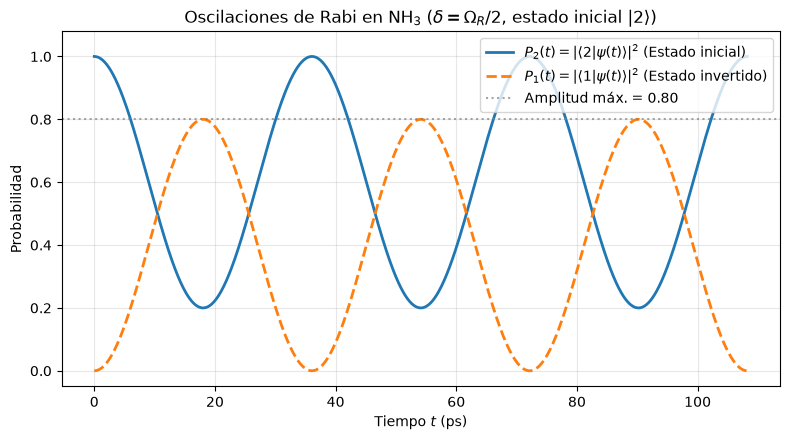

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros del sistema (NH3)
f_R = 24.79e9                  # Frecuencia de Rabi resonante en Hz (24.79 GHz)
Omega_R = 2 * np.pi * f_R      # Frecuencia angular de Rabi en rad/s
delta = Omega_R / 2            # Desintonía (detuning) = Omega_R / 2

# 2. Frecuencia de Rabi generalizada (efectiva) en Hz
Omega_eff = np.sqrt(Omega_R**2 + delta**2)
f_eff = Omega_eff / (2 * np.pi)
T_eff = 1 / f_eff              # Período de oscilación en segundos
P_max = (Omega_R**2) / (Omega_R**2 + delta**2)

print(f"Frecuencia de Rabi resonante (f_R):  {f_R:.4e} Hz ({f_R/1e9:.2f} GHz)")
print(f"Frecuencia de desintonía (f_delta):  {delta/(2*np.pi):.4e} Hz ({delta/(2*np.pi*1e9):.3f} GHz)")
print(f"Frecuencia de Rabi efectiva (f_eff): {f_eff:.4e} Hz ({f_eff/1e9:.2f} GHz)")
print(f"Período de oscilación (T_eff):       {T_eff*1e12:.2f} ps")
print(f"Amplitud máxima de transición:       {P_max:.2f}")

# 3. Evolución temporal (3 períodos completos)
t = np.linspace(0, 3 * T_eff, 1000)

# Estado inicial |psi(0)> = |2> -> P_2(0) = 1, P_1(0) = 0
P_1 = P_max * np.sin(0.5 * Omega_eff * t)**2   # Transición |2> -> |1>
P_2 = 1.0 - P_1                                 # Permanencia en |2>

# 4. Gráfica de las oscilaciones de Rabi
plt.figure(figsize=(8, 4.5))
plt.plot(t * 1e12, P_2, label=r'$P_2(t) = |\langle 2|\psi(t)\rangle|^2$ (Estado inicial)', linewidth=2)
plt.plot(t * 1e12, P_1, '--', label=r'$P_1(t) = |\langle 1|\psi(t)\rangle|^2$ (Estado invertido)', linewidth=2)

plt.axhline(P_max, color='gray', linestyle=':', alpha=0.7, label=f'Amplitud máx. = {P_max:.2f}')
plt.title(r'Oscilaciones de Rabi en $\mathrm{NH}_3$ ($\delta = \Omega_R/2$, estado inicial $|2\rangle$)')
plt.xlabel('Tiempo $t$ (ps)')
plt.ylabel('Probabilidad')
plt.ylim(-0.05, 1.08)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()